# Tarea 4 · Árboles de regresión
## Predicción de la resistencia a compresión del concreto
**Curso:** Aprendizaje Supervisado · **Base:** Concrete_Data.csv

Se adapta el procedimiento de `Arboles/arbolespython.ipynb` a la base del estudiante. La respuesta es la resistencia a compresión en MPa y los ocho predictores describen la mezcla y su edad. El objetivo es construir, interpretar y optimizar un árbol de regresión.

El cuaderno incluye código ejecutado, resultados, validación cruzada, poda y conclusiones. La carpeta Tarea4 no contiene una consigna adicional; se sigue el material de clase.

In [1]:
import sys, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.model_selection import (train_test_split, GroupShuffleSplit, GroupKFold,
    GridSearchCV, RandomizedSearchCV, validation_curve, learning_curve, cross_val_score)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from scipy.stats import randint, uniform
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
rutas = [Path('../../Concrete_Data.csv'), Path('Concrete_Data.csv')]
ruta = next((p for p in rutas if p.exists()), None)
if ruta is None: raise FileNotFoundError('Coloca Concrete_Data.csv en la raíz del proyecto.')
datos_originales = pd.read_csv(ruta)
nombres = ['Cemento', 'Escoria', 'Ceniza', 'Agua', 'Superplastificante',
           'Agregado_grueso', 'Agregado_fino', 'Edad', 'Resistencia']
assert datos_originales.shape[1] == 9
datos = datos_originales.copy()
datos.columns = nombres
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('SHA256 de la base:', hashlib.sha256(ruta.read_bytes()).hexdigest())
print('Dimensiones:', datos.shape)
display(pd.DataFrame({'Nombre original': datos_originales.columns, 'Nombre usado': nombres,
                      'Unidad': ['kg/m³']*7 + ['días', 'MPa']}))
display(datos.head())

Python: 3.12.14 | scikit-learn: 1.9.1
SHA256 de la base: bb2d7905b43cc168a4da093b98689a813f07c7afbe0f75c8f4ef631a97981359
Dimensiones: (1030, 9)


,Nombre original,Nombre usado,Unidad
0,Cement (component 1)(kg in a m^3 mixture),Cemento,kg/m³
1,Blast Furnace Slag (component 2)(kg in a m^3 m...,Escoria,kg/m³
2,Fly Ash (component 3)(kg in a m^3 mixture),Ceniza,kg/m³
3,Water (component 4)(kg in a m^3 mixture),Agua,kg/m³
4,Superplasticizer (component 5)(kg in a m^3 mix...,Superplastificante,kg/m³
5,Coarse Aggregate (component 6)(kg in a m^3 mi...,Agregado_grueso,kg/m³
6,Fine Aggregate (component 7)(kg in a m^3 mixture),Agregado_fino,kg/m³
7,Age (day),Edad,días
8,"Concrete compressive strength(MPa, megapascals)",Resistencia,MPa


,Cemento,Escoria,Ceniza,Agua,Superplastificante,Agregado_grueso,Agregado_fino,Edad,Resistencia
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


## 1. Inspección y estadística descriptiva
Todas las variables son numéricas. No se requiere codificación categórica ni estandarización para un árbol. Se revisan nulos, duplicados y rangos antes de entrenar. No se eliminan valores extremos automáticamente: pueden corresponder a mezclas reales.

,count,mean,std,min,25%,50%,75%,max
Cemento,1030.0,281.166,104.507,102.000,192.375,272.900,350.000,540.000
Escoria,1030.0,73.895,86.279,0.000,0.000,22.000,142.950,359.400
Ceniza,1030.0,54.187,63.996,0.000,0.000,0.000,118.270,200.100
Agua,1030.0,181.566,21.356,121.750,164.900,185.000,192.000,247.000
Superplastificante,1030.0,6.203,5.973,0.000,0.000,6.350,10.160,32.200
Agregado_grueso,1030.0,972.919,77.754,801.000,932.000,968.000,1029.400,1145.000
Agregado_fino,1030.0,773.579,80.175,594.000,730.950,779.510,824.000,992.600
Edad,1030.0,45.662,63.170,1.000,7.000,28.000,56.000,365.000
Resistencia,1030.0,35.818,16.706,2.332,23.707,34.443,46.136,82.599


Nulos por columna:
Cemento               0
Escoria               0
Ceniza                0
Agua                  0
Superplastificante    0
Agregado_grueso       0
Agregado_fino         0
Edad                  0
Resistencia           0
Filas exactamente duplicadas: 25


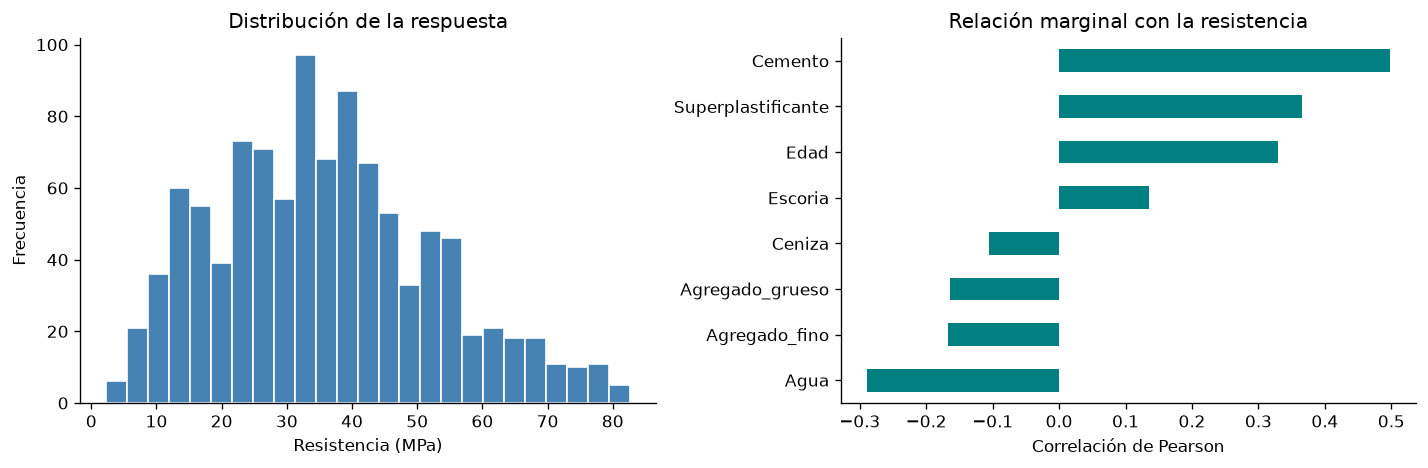

In [2]:
display(datos.describe().T.round(3))
print('Nulos por columna:'); print(datos.isna().sum().to_string())
print('Filas exactamente duplicadas:', datos.duplicated().sum())
assert not datos.isna().any().any()
assert np.isfinite(datos.to_numpy()).all()
assert (datos >= 0).all().all()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(datos.Resistencia, bins=25, color='steelblue', edgecolor='white')
axes[0].set(xlabel='Resistencia (MPa)', ylabel='Frecuencia', title='Distribución de la respuesta')
corr = datos.corr()['Resistencia'].drop('Resistencia').sort_values()
corr.plot.barh(ax=axes[1], color='teal')
axes[1].set(xlabel='Correlación de Pearson', title='Relación marginal con la resistencia')
plt.tight_layout(); plt.show()

## 2. Separación de entrenamiento y prueba
Se reserva aproximadamente el 20% para prueba con semilla 42. Para evitar que mezclas idénticas y edades idénticas aparezcan en ambos conjuntos, se agrupan las filas con los mismos ocho predictores. La validación cruzada también respeta estos grupos. Se conservan las mediciones repetidas, pero nunca se reparten entre entrenamiento y validación. Esta evaluación mide generalización a combinaciones de mezcla y edad no vistas; no garantiza independencia entre edades distintas de una misma formulación.

In [3]:
X = datos.drop(columns='Resistencia')
y = datos.Resistencia
grupos = pd.util.hash_pandas_object(X, index=False).to_numpy()
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(split.split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train = grupos[idx_train]
assert not set(g_train).intersection(grupos[idx_test])
cv = list(GroupKFold(n_splits=5).split(X_train, y_train, groups=g_train))
print(f'Entrenamiento: {len(X_train)} ({len(X_train)/len(X):.1%})')
print(f'Prueba: {len(X_test)} ({len(X_test)/len(X):.1%})')
print('Predictores:', X.shape[1], '| Grupos compartidos entre train y test: 0')

Entrenamiento: 828 (80.4%)
Prueba: 202 (19.6%)
Predictores: 8 | Grupos compartidos entre train y test: 0


## 3. Árbol inicial y referencia
Se entrena el árbol controlado del ejemplo de clase (profundidad 5, mínimo de 20 muestras para dividir y 10 por hoja), un árbol sin restricciones y una referencia que siempre predice la media de entrenamiento. El criterio `squared_error` busca reducir el error cuadrático. Cada hoja predice la media de las respuestas que llegaron a ella.

In [4]:
modelos = {
    'Media de entrenamiento': DummyRegressor(strategy='mean'),
    'Árbol sin restricciones': DecisionTreeRegressor(random_state=42),
    'Árbol inicial': DecisionTreeRegressor(max_depth=5, min_samples_split=20,
                                         min_samples_leaf=10, random_state=42)
}
for modelo in modelos.values(): modelo.fit(X_train, y_train)
inicial = modelos['Árbol inicial']
print('Profundidad inicial:', inicial.get_depth(), '| Hojas:', inicial.get_n_leaves())
scores = -cross_val_score(inicial, X_train, y_train, cv=cv,
                         scoring='neg_root_mean_squared_error', n_jobs=1)
print('RMSE por fold:', np.round(scores, 3))
print(f'RMSE CV: {scores.mean():.3f} ± {scores.std():.3f} MPa')

Profundidad inicial: 5 | Hojas: 27
RMSE por fold: [8.759 9.056 7.88  8.161 8.533]
RMSE CV: 8.478 ± 0.418 MPa


## 4. Curva de validación y optimización
Los hiperparámetros se eligen usando exclusivamente entrenamiento y validación cruzada. Se utiliza la misma partición de cinco grupos en ambas búsquedas. Se omite `max_features="auto"` del ejemplo porque no es una opción válida en versiones recientes. La búsqueda exhaustiva y la aleatoria se comparan por RMSE de validación, sin consultar la prueba para elegir el modelo.

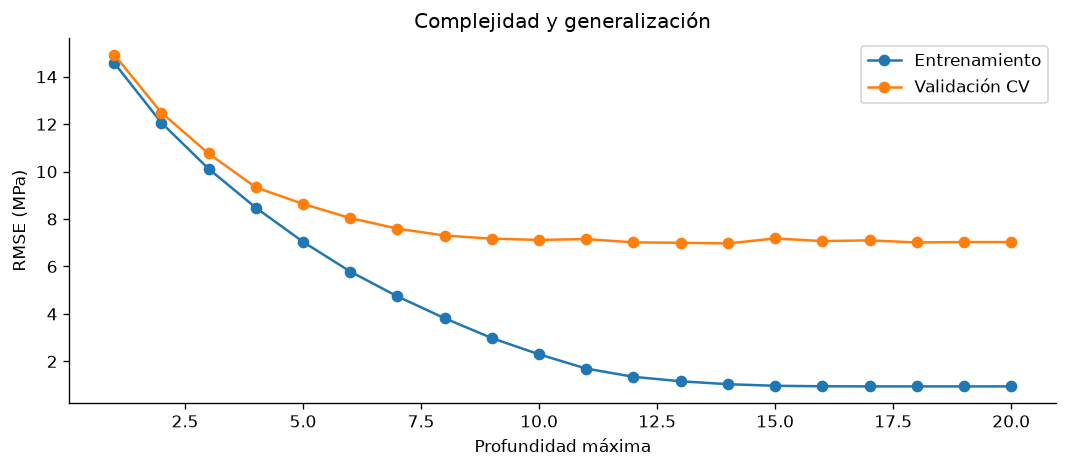

GridSearchCV | combinaciones: 240
Mejores parámetros: {'max_depth': 12, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'}
RMSE CV: 7.0180 MPa
RandomizedSearchCV | combinaciones: 80
Mejores parámetros: {'max_depth': 10, 'max_features': None, 'min_impurity_decrease': np.float64(0.038867728968948204), 'min_samples_leaf': 2, 'min_samples_split': 16, 'splitter': 'best'}
RMSE CV: 7.5379 MPa


,params,mean_test_score,std_test_score
144,"{'max_depth': 12, 'max_features': None, 'min_s...",-7.017969,0.541717
192,"{'max_depth': None, 'max_features': None, 'min...",-7.030602,0.561387
194,"{'max_depth': None, 'max_features': None, 'min...",-7.194073,0.437012
146,"{'max_depth': 12, 'max_features': None, 'min_s...",-7.203231,0.456206
204,"{'max_depth': None, 'max_features': None, 'min...",-7.303539,0.261100


In [5]:
profundidades = np.arange(1, 21)
tr, va = validation_curve(DecisionTreeRegressor(random_state=42), X_train, y_train,
    param_name='max_depth', param_range=profundidades, cv=cv,
    scoring='neg_root_mean_squared_error', n_jobs=1)
plt.figure(figsize=(9, 4))
plt.plot(profundidades, -tr.mean(axis=1), 'o-', label='Entrenamiento')
plt.plot(profundidades, -va.mean(axis=1), 'o-', label='Validación CV')
plt.xlabel('Profundidad máxima'); plt.ylabel('RMSE (MPa)')
plt.title('Complejidad y generalización'); plt.legend(); plt.tight_layout(); plt.show()
grid = GridSearchCV(DecisionTreeRegressor(random_state=42), {
    'max_depth': [3, 5, 8, 12, None], 'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 3, 5, 10], 'max_features': [None, 'sqrt'],
    'splitter': ['best', 'random']}, cv=cv,
    scoring='neg_root_mean_squared_error', n_jobs=1, error_score='raise')
grid.fit(X_train, y_train)
random = RandomizedSearchCV(DecisionTreeRegressor(random_state=42), {
    'max_depth': randint(3, 21), 'min_samples_split': randint(2, 31),
    'min_samples_leaf': randint(1, 11), 'max_features': [None, 'sqrt', 'log2'],
    'min_impurity_decrease': uniform(0, 0.1), 'splitter': ['best', 'random']},
    n_iter=80, random_state=42, cv=cv, scoring='neg_root_mean_squared_error',
    n_jobs=1, error_score='raise')
random.fit(X_train, y_train)
for nombre, busqueda in [('GridSearchCV', grid), ('RandomizedSearchCV', random)]:
    print(nombre, '| combinaciones:', len(busqueda.cv_results_['params']))
    print('Mejores parámetros:', busqueda.best_params_)
    print(f'RMSE CV: {-busqueda.best_score_:.4f} MPa')
display(pd.DataFrame(grid.cv_results_).sort_values('rank_test_score')
        [['params', 'mean_test_score', 'std_test_score']].head(5))

## 5. Poda por coste y complejidad
`ccp_alpha` penaliza el tamaño del árbol. Se evalúa una rejilla fijada de antemano, incluido cero (sin poda). Así los candidatos no se calculan usando las respuestas de los pliegues de validación. Se elige alpha por RMSE CV, no por número de hojas arbitrario.

Mejor alpha: 0.006614740641230145
RMSE CV de poda: 7.0261 MPa
Profundidad podada: 17 | Hojas: 379


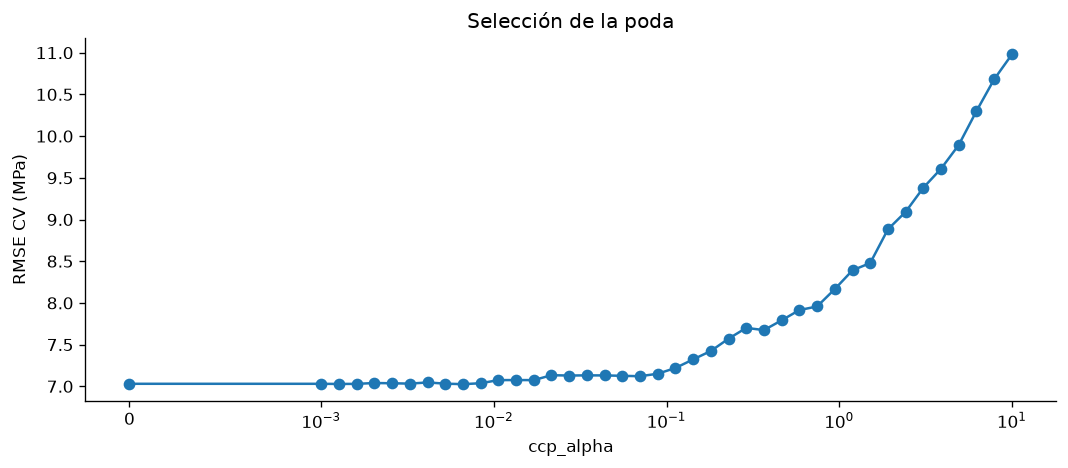

Modelo elegido antes de evaluar prueba: GridSearchCV


In [6]:
poda = GridSearchCV(DecisionTreeRegressor(random_state=42),
    {'ccp_alpha': np.r_[0, np.logspace(-3, 1, 40)]}, cv=cv,
    scoring='neg_root_mean_squared_error', n_jobs=1, error_score='raise')
poda.fit(X_train, y_train)
print('Mejor alpha:', poda.best_params_['ccp_alpha'])
print(f'RMSE CV de poda: {-poda.best_score_:.4f} MPa')
print('Profundidad podada:', poda.best_estimator_.get_depth(),
      '| Hojas:', poda.best_estimator_.get_n_leaves())
plt.figure(figsize=(9, 4))
plt.plot(poda.cv_results_['param_ccp_alpha'].astype(float),
         -poda.cv_results_['mean_test_score'], 'o-')
plt.xscale('symlog', linthresh=0.001); plt.xlabel('ccp_alpha'); plt.ylabel('RMSE CV (MPa)')
plt.title('Selección de la poda'); plt.tight_layout(); plt.show()
busquedas = {'GridSearchCV': grid, 'RandomizedSearchCV': random, 'Árbol podado': poda}
seleccion = max(busquedas, key=lambda nombre: busquedas[nombre].best_score_)
mejor = busquedas[seleccion].best_estimator_
modelos.update({nombre: b.best_estimator_ for nombre, b in busquedas.items()})
print('Modelo elegido antes de evaluar prueba:', seleccion)

## 6. Evaluación final en prueba
MAE y RMSE se expresan en MPa; MSE en MPa². R² compara el error del modelo con la variación respecto a la media de prueba. El resultado corresponde a esta partición, y no demuestra causalidad ni garantiza desempeño en otras mezclas. La selección permanece fijada por CV incluso si otro modelo obtiene mejor resultado en prueba.

,MAE,MSE,RMSE,R²,RMSE train
Modelo,,,,,
Media de entrenamiento,12.7767,252.5348,15.8913,-0.0138,16.8933
Árbol sin restricciones,4.0263,40.3904,6.3553,0.8379,1.0130
Árbol inicial,6.1725,74.0382,8.6045,0.7028,7.4195
GridSearchCV,4.2999,44.2038,6.6486,0.8226,1.6506
RandomizedSearchCV,5.2440,54.4306,7.3777,0.7815,4.5706
Árbol podado,4.1478,40.7184,6.3811,0.8365,1.2398


,Real (MPa),Predicho (MPa),Residuo (MPa)
3,41.053,40.270,0.783
4,44.296,38.074,6.222
5,47.030,46.071,0.959
15,52.908,54.276,-1.367
16,39.358,43.377,-4.019
26,41.151,43.013,-1.862
32,41.720,38.074,3.645
38,42.229,42.621,-0.392
40,50.459,46.071,4.388
44,41.543,41.837,-0.294


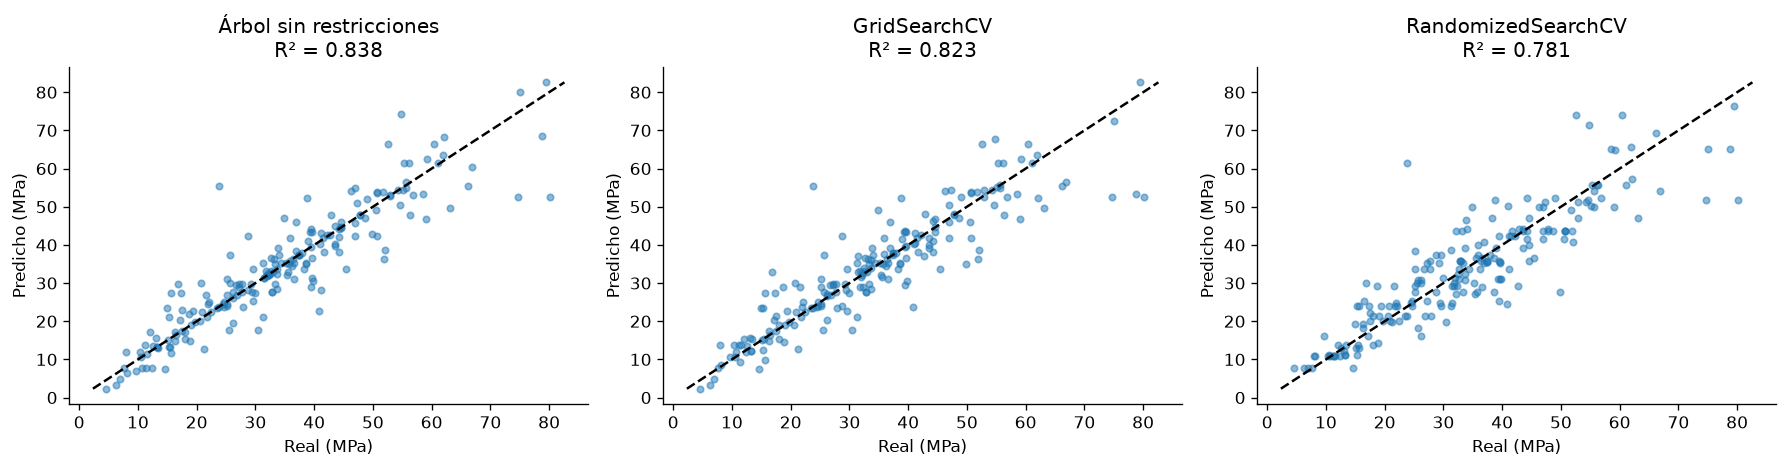

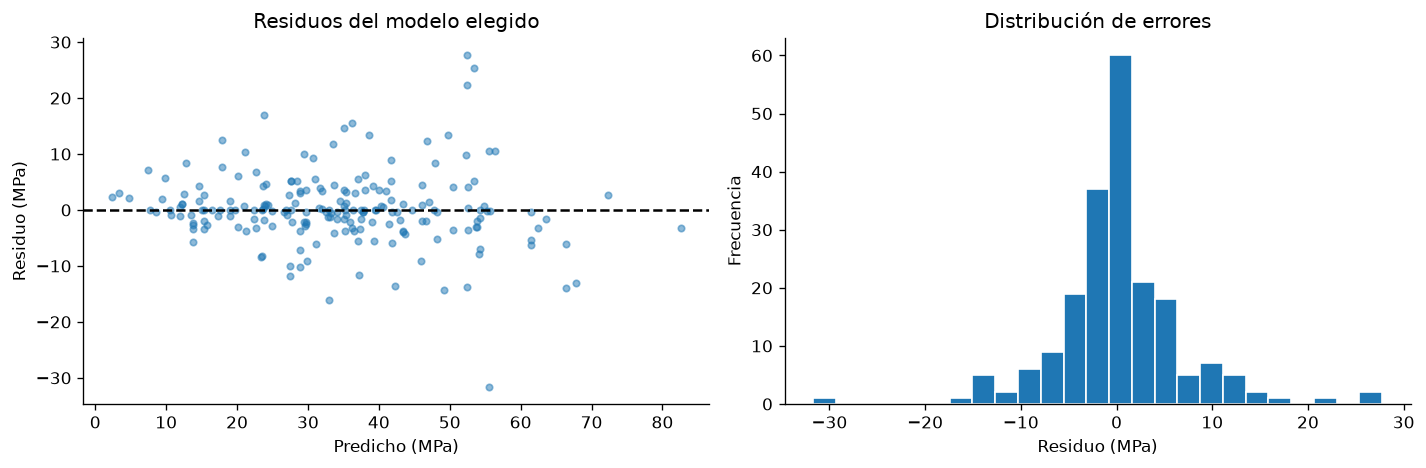

In [7]:
def metricas(real, pred):
    return {'MAE': mean_absolute_error(real, pred), 'MSE': mean_squared_error(real, pred),
            'RMSE': np.sqrt(mean_squared_error(real, pred)), 'R²': r2_score(real, pred)}
filas = []
for nombre, modelo in modelos.items():
    fila = {'Modelo': nombre, **metricas(y_test, modelo.predict(X_test)),
            'RMSE train': np.sqrt(mean_squared_error(y_train, modelo.predict(X_train)))}
    filas.append(fila)
resultados = pd.DataFrame(filas).set_index('Modelo')
display(resultados.round(4))
pred = mejor.predict(X_test)
comparacion = pd.DataFrame({'Real (MPa)': y_test, 'Predicho (MPa)': pred,
                           'Residuo (MPa)': y_test - pred})
display(comparacion.head(10).round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nombre in zip(axes, ['Árbol sin restricciones', 'GridSearchCV', 'RandomizedSearchCV']):
    p = modelos[nombre].predict(X_test)
    ax.scatter(y_test, p, alpha=.5, s=15)
    ax.plot([y.min(), y.max()], [y.min(), y.max()], 'k--')
    ax.set(xlabel='Real (MPa)', ylabel='Predicho (MPa)', title=f'{nombre}\nR² = {r2_score(y_test,p):.3f}')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pred, y_test-pred, s=15, alpha=.5)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(xlabel='Predicho (MPa)', ylabel='Residuo (MPa)', title='Residuos del modelo elegido')
axes[1].hist(y_test-pred, bins=25, edgecolor='white')
axes[1].set(xlabel='Residuo (MPa)', ylabel='Frecuencia', title='Distribución de errores')
plt.tight_layout(); plt.show()

## 7. Curva de aprendizaje
Se utiliza el modelo elegido y los mismos pliegues de grupos. La separación entre entrenamiento y validación permite diagnosticar sobreajuste; la curva es descriptiva y no interviene en la selección posterior.

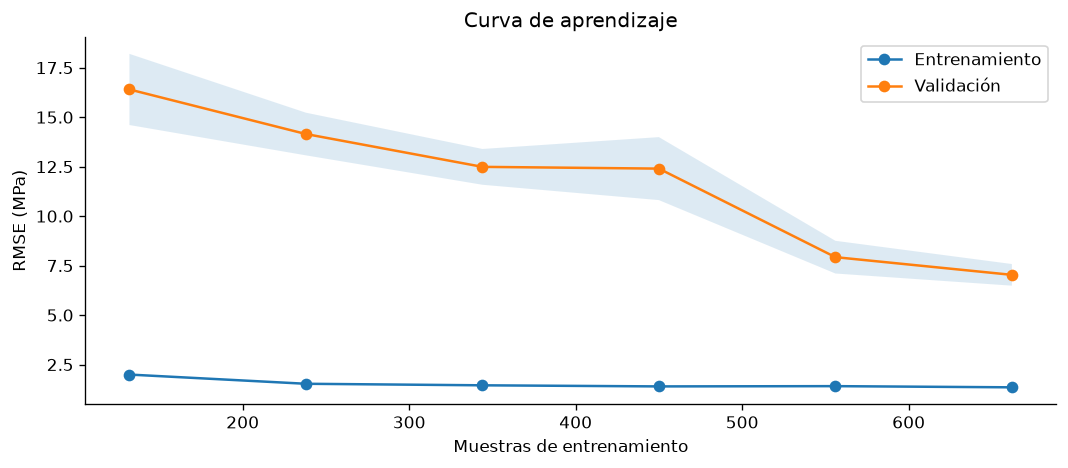

In [8]:
sizes, st, sv = learning_curve(mejor, X_train, y_train, cv=cv,
    train_sizes=np.linspace(.2, 1, 6), scoring='neg_root_mean_squared_error', n_jobs=1)
plt.figure(figsize=(9, 4))
plt.plot(sizes, -st.mean(axis=1), 'o-', label='Entrenamiento')
plt.plot(sizes, -sv.mean(axis=1), 'o-', label='Validación')
plt.fill_between(sizes, -sv.mean(axis=1)-sv.std(axis=1),
                 -sv.mean(axis=1)+sv.std(axis=1), alpha=.15)
plt.xlabel('Muestras de entrenamiento'); plt.ylabel('RMSE (MPa)')
plt.title('Curva de aprendizaje'); plt.legend(); plt.tight_layout(); plt.show()

## 8. Interpretación del árbol y de sus variables
El gráfico muestra los primeros tres niveles del **mismo modelo elegido**, truncados para facilitar la lectura; no se entrena un árbol distinto para representarlo. Las reglas completas se guardan en un archivo de texto. La importancia por impureza mide reducción del error en entrenamiento y puede favorecer determinadas variables. Se complementa con permutación en prueba, utilizada solo para interpretación, sin reajustar el modelo.

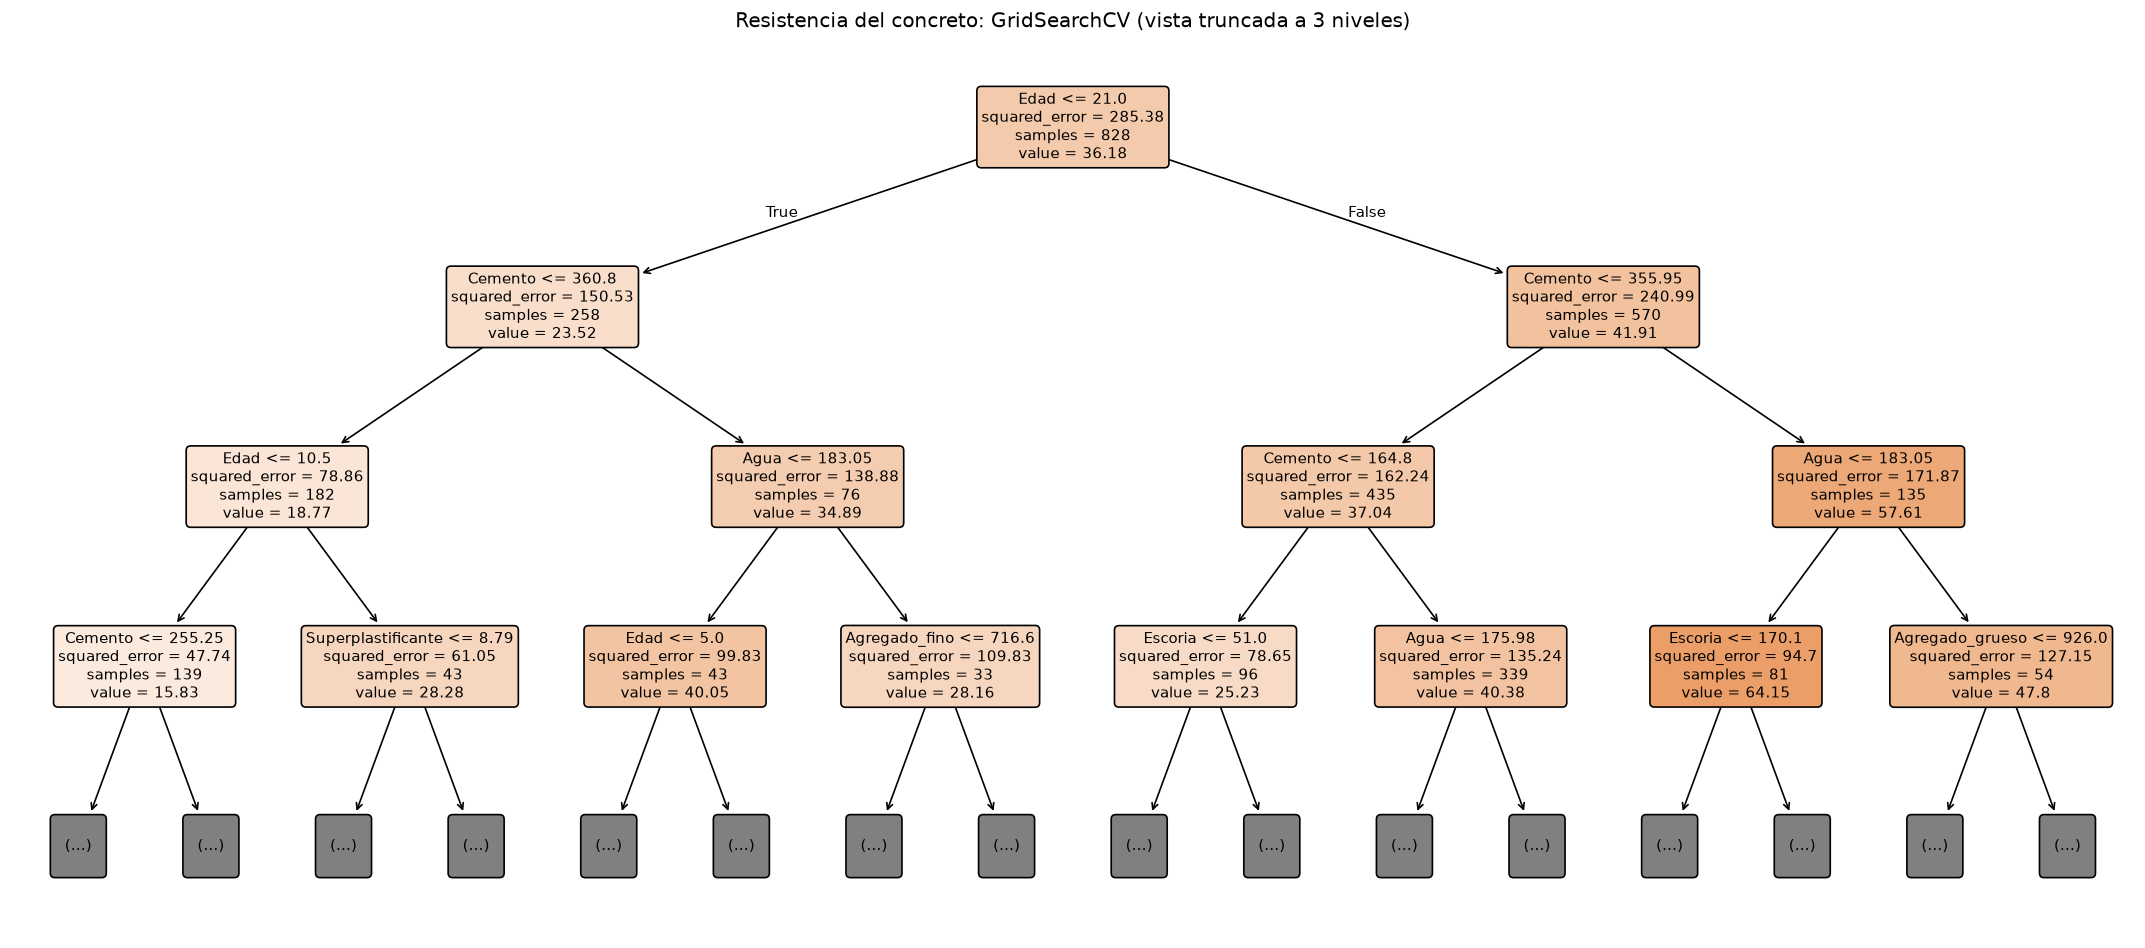

Profundidad: 12 | Hojas: 559
Primeras 50 líneas de las reglas:
|--- Edad <= 21.000
|   |--- Cemento <= 360.800
|   |   |--- Edad <= 10.500
|   |   |   |--- Cemento <= 255.250
|   |   |   |   |--- Cemento <= 155.000
|   |   |   |   |   |--- Edad <= 5.000
|   |   |   |   |   |   |--- Agregado_grueso <= 1009.400
|   |   |   |   |   |   |   |--- Cemento <= 131.950
|   |   |   |   |   |   |   |   |--- Cemento <= 115.450
|   |   |   |   |   |   |   |   |   |--- value: [2.332]
|   |   |   |   |   |   |   |   |--- Cemento >  115.450
|   |   |   |   |   |   |   |   |   |--- value: [3.320]
|   |   |   |   |   |   |   |--- Cemento >  131.950
|   |   |   |   |   |   |   |   |--- Agregado_grueso <= 929.900
|   |   |   |   |   |   |   |   |   |--- value: [4.782]
|   |   |   |   |   |   |   |   |--- Agregado_grueso >  929.900
|   |   |   |   |   |   |   |   |   |--- value: [4.828]
|   |   |   |   |   |   |--- Agregado_grueso >  1009.400
|   |   |   |   |   |   |   |--- value: [8.063]
|   |   |   |   

,Impureza,Aumento RMSE por permutación,Desviación permutación
Agregado_fino,0.0186,0.7129,0.1496
Agregado_grueso,0.0387,1.3576,0.5431
Agua,0.1062,5.7526,0.6868
Cemento,0.3727,10.3343,0.7448
Ceniza,0.0117,0.3426,0.1800
Edad,0.3333,9.1141,0.4287
Escoria,0.0909,4.7915,0.5084
Superplastificante,0.0280,1.8178,0.3317


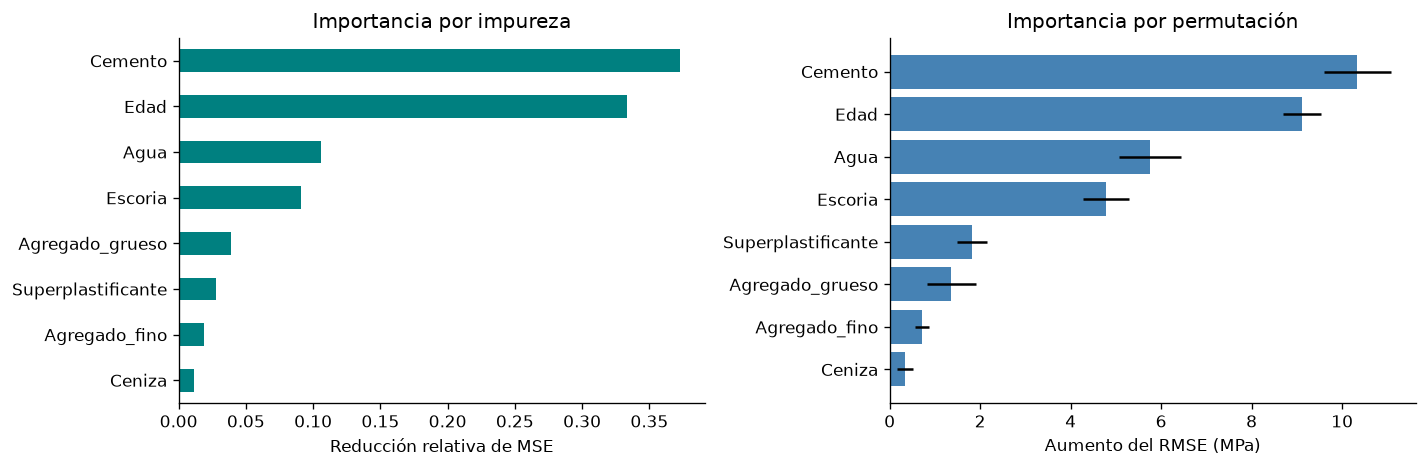

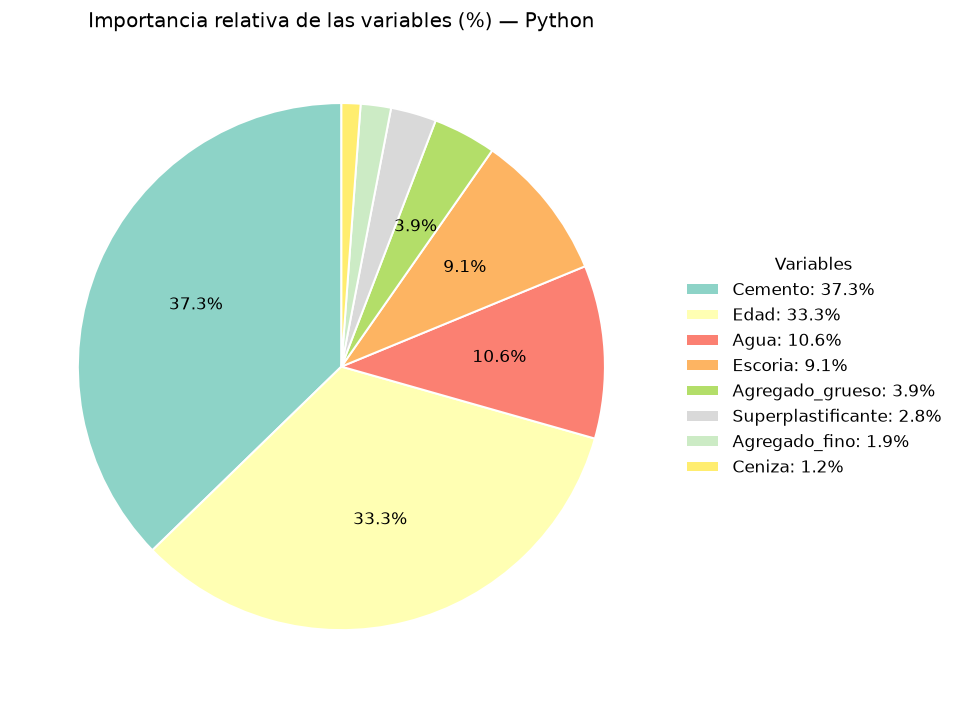

El circular reparte la importancia por impureza entre variables. No representa el porcentaje de resistencia explicado por cada una.


In [9]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(mejor, feature_names=list(X.columns), max_depth=3,
          filled=True, rounded=True, fontsize=9, precision=2, ax=ax)
ax.set_title(f'Resistencia del concreto: {seleccion} (vista truncada a 3 niveles)')
plt.tight_layout(); plt.show()
reglas = export_text(mejor, feature_names=list(X.columns), max_depth=100, decimals=3)
Path('reglas_arbol_concrete.txt').write_text(reglas, encoding='utf-8')
print('Profundidad:', mejor.get_depth(), '| Hojas:', mejor.get_n_leaves())
print('Primeras 50 líneas de las reglas:')
print('\n'.join(reglas.splitlines()[:50]))
imp = pd.Series(mejor.feature_importances_, index=X.columns).sort_values(ascending=False)
perm = permutation_importance(mejor, X_test, y_test, n_repeats=20, random_state=42,
                              scoring='neg_root_mean_squared_error', n_jobs=1)
tabla_imp = pd.DataFrame({'Impureza': imp, 'Aumento RMSE por permutación':
                         pd.Series(perm.importances_mean, index=X.columns),
                         'Desviación permutación': pd.Series(perm.importances_std, index=X.columns)})
display(tabla_imp.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
imp.sort_values().plot.barh(ax=axes[0], color='teal')
axes[0].set(title='Importancia por impureza', xlabel='Reducción relativa de MSE')
orden = np.argsort(perm.importances_mean)
axes[1].barh(np.array(X.columns)[orden], perm.importances_mean[orden],
             xerr=perm.importances_std[orden], color='steelblue')
axes[1].set(title='Importancia por permutación', xlabel='Aumento del RMSE (MPa)')
plt.tight_layout(); plt.show()
# Circular del ejemplo: distribución de importancia por impureza.
imp_positiva = imp[imp > 0]
fig, ax = plt.subplots(figsize=(10, 6))
porciones, _, _ = ax.pie(imp_positiva, autopct=lambda p: f'{p:.1f}%' if p >= 3 else '', startangle=90,
    colors=plt.cm.Set3(np.linspace(0, 1, len(imp_positiva))),
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.2})
etiquetas = [f'{nombre}: {valor / imp_positiva.sum():.1%}' for nombre, valor in imp_positiva.items()]
ax.legend(porciones, etiquetas, title='Variables', loc='center left',
          bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title('Importancia relativa de las variables (%) — Python')
ax.set_aspect('equal')
plt.tight_layout(); plt.show()
print('El circular reparte la importancia por impureza entre variables. No representa el porcentaje de resistencia explicado por cada una.')

## 9. Predicción de una mezcla propuesta
Ejemplo ilustrativo: cantidades de componentes en kg/m³ y edad en días. La resistencia es una estimación, no una certificación de ingeniería. Los árboles no extrapolan de forma fiable fuera de los rangos observados.

In [10]:
nueva = pd.DataFrame([[300, 100, 0, 180, 6, 1000, 800, 28]], columns=X.columns)
display(nueva)
print(f'Resistencia estimada: {mejor.predict(nueva)[0]:.3f} MPa')
for col in X.columns:
    if not X_train[col].min() <= nueva[col].iloc[0] <= X_train[col].max():
        print('Fuera del rango de entrenamiento:', col)

,Cemento,Escoria,Ceniza,Agua,Superplastificante,Agregado_grueso,Agregado_fino,Edad
0,300,100,0,180,6,1000,800,28


Resistencia estimada: 41.051 MPa


## 10. Conclusiones basadas en los resultados

In [11]:
m = resultados.loc[seleccion]
base = resultados.loc['Árbol sin restricciones']
print(f'1. Se eligió {seleccion} por el menor RMSE en validación cruzada de entrenamiento.')
print(f'2. En prueba: MAE = {m.MAE:.3f} MPa, RMSE = {m.RMSE:.3f} MPa y R² = {m["R²"]:.4f}.')
cambio = (base.RMSE-m.RMSE)/base.RMSE*100
sentido = 'redujo' if cambio >= 0 else 'aumentó'
print(f'3. Frente al árbol sin restricciones, el RMSE {sentido} {abs(cambio):.2f}%. La optimización por CV no garantiza mejora en esta prueba.')
print('4. Variables principales por impureza:', ', '.join(imp.head(3).index)+'.')
print('5. La importancia describe el uso predictivo de las variables; no establece efectos causales.')
print('6. Los resultados se limitan a una partición de esta base. Se requiere validación externa para otras formulaciones.')
resultados.to_csv('metricas_arboles_concrete.csv', encoding='utf-8-sig')
comparacion.to_csv('predicciones_prueba_concrete.csv', encoding='utf-8-sig', index_label='Fila original')

1. Se eligió GridSearchCV por el menor RMSE en validación cruzada de entrenamiento.
2. En prueba: MAE = 4.300 MPa, RMSE = 6.649 MPa y R² = 0.8226.
3. Frente al árbol sin restricciones, el RMSE aumentó 4.61%. La optimización por CV no garantiza mejora en esta prueba.
4. Variables principales por impureza: Cemento, Edad, Agua.
5. La importancia describe el uso predictivo de las variables; no establece efectos causales.
6. Los resultados se limitan a una partición de esta base. Se requiere validación externa para otras formulaciones.


## Reproducibilidad y material utilizado
- Base local: `Concrete_Data.csv` (huella SHA256 mostrada al inicio).
- Guía: `Arboles/arbolespython.ipynb`, `arbolesderegresion.r` y PDFs de clase.
- Semilla: 42; selección con cinco pliegues de grupos y RMSE.
- Se conserva la base original y se adapta la respuesta y las unidades al concreto.

Para reproducir: abrir este `.ipynb` desde `Arboles/Tarea4`, instalar las dependencias indicadas en `requirements.txt` y ejecutar todas las celdas. El HTML contiene las salidas y figuras embebidas y puede leerse sin conexión.

## Árbol completo del modelo seleccionado
Se conserva el mismo modelo; la figura anterior es una vista truncada. Esta figura permite inspeccionar todos los nodos.

In [12]:
fig, ax = plt.subplots(figsize=(max(22, mejor.get_n_leaves() * .32), max(10, mejor.get_depth() * 1.4)))
plot_tree(mejor, feature_names=list(X.columns), filled=True, rounded=True, fontsize=5, precision=2, ax=ax)
ax.set_title("Árbol completo del modelo seleccionado")
fig.savefig("arbol_completo_python.svg", bbox_inches="tight")
plt.close(fig)
print("Árbol completo guardado en arbol_completo_python.svg")

Árbol completo guardado en arbol_completo_python.svg
